## Median house value prediction in California

## Download the data

In [1]:
from pathlib import Path
import pandas as pd
import tarfile
import urllib.request

def fetch_housing_data():
    tarball_path = Path("datasets/housing.tgz")
    if not tarball_path.is_file():
        Path('datasets').mkdir(parents=True, exist_ok=True)
        url = "https://github.com/ageron/data/raw/main/housing.tgz"
        urllib.request.urlretrieve(url, tarball_path)

        with(tarfile.open(tarball_path)) as housing_tarball:
            housing_tarball.extractall(path="datasets")

    return pd.read_csv("datasets/housing/housing.csv")
housing = fetch_housing_data()
housing.head(3)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY


### Description and summary of data

In [2]:
housing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


Here, it's key to observe the total_bedrooms feature has only 20,433 non-null values, i.e., 207 districts are missing this feature.

In [3]:
housing.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


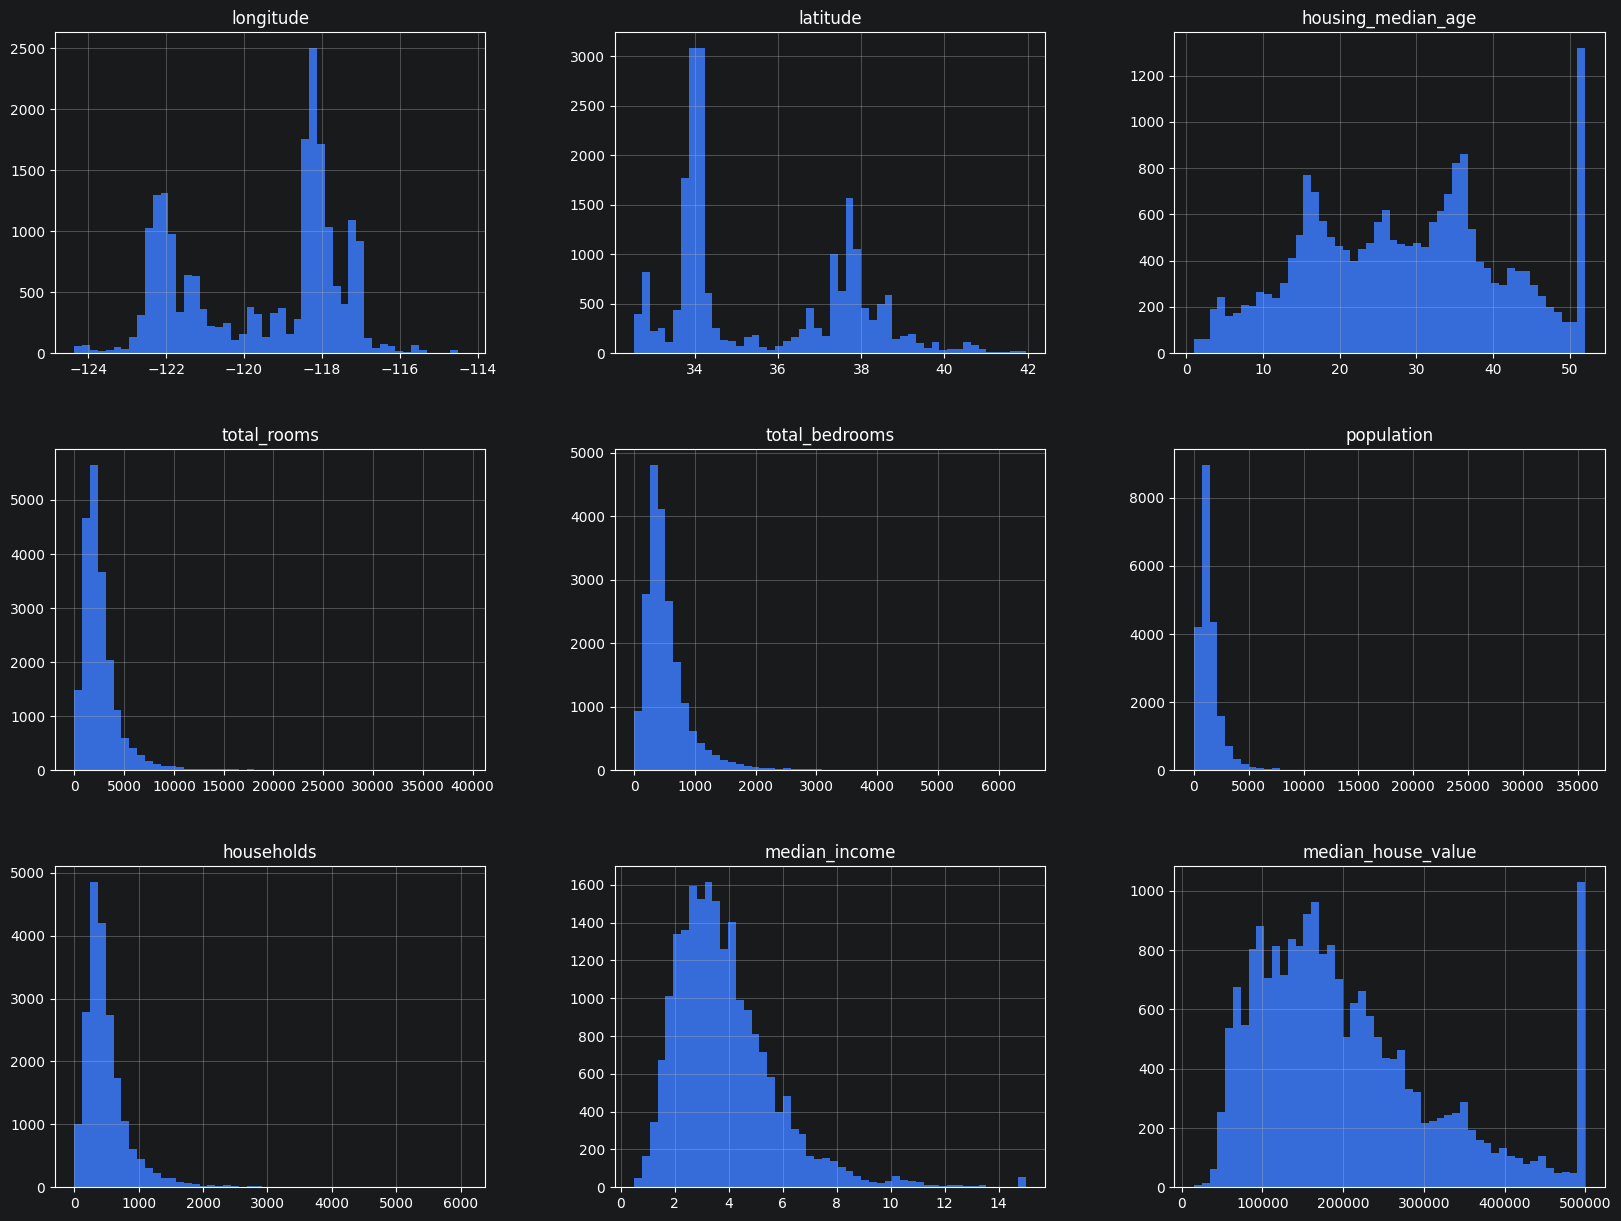

In [5]:
import matplotlib.pyplot as plt
housing.hist(bins=50, figsize=(20,15))  
plt.show()

## Creat Test Set
1. We need the test set created to same every time we run the program, if we use np.random.permutation(len(data)) the random number generated is random and vary everytime we rerun it. That way we and the model will see the test data.

2. To solve that problem we may use random seed so we always have same train and test set, but completely random splitting is somehow skewed. For Ex. whole dataset:80% low income, 20% high income then Random test set: 95% low income, 5% high income 
the model is then tested on a test set that doesn't properly represent the real data → sampling bias. To solve that isssue we use segmented groups or data chunk called strata.

3. To make the test set more representative, we use **stratified sampling**. We divide the data into meaningful groups called **strata**, such as income categories, and make sure each group is represented in the test set in roughly the same proportion as in the full dataset. This reduces the risk of **sampling bias** and gives us a test set that better represents the real dataset.

In [5]:
from sklearn.model_selection import train_test_split
train_set, test_set = train_test_split(housing, test_size=0.2, random_state=42)  # Purely random split

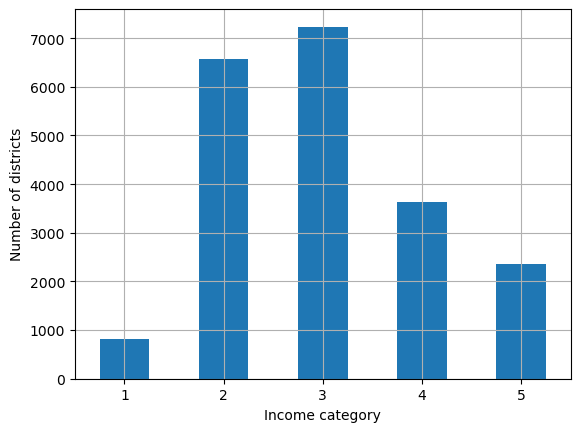

In [6]:
import numpy as np
housing["income_cat"] = pd.cut(housing["median_income"],
bins=[0., 1.5, 3.0, 4.5, 6., np.inf], labels=[1, 2, 3, 4, 5])  # Split the income into 5 categories, most important feature for price prediction

housing["income_cat"].value_counts().sort_index().plot.bar(rot=0, 
grid=True)
plt.xlabel("Income category")
plt.ylabel("Number of districts")
plt.show()

In [7]:
from sklearn.model_selection import train_test_split

strat_train_set, strat_test_set = train_test_split(
    housing,
    test_size=0.2,
    random_state=42,
    stratify=housing["income_cat"]   # Income cat is median income segemented into 5 categories, so we can use it for stratified sampling.
)

for set_ in (strat_train_set, strat_test_set):
    set_.drop("income_cat", axis=1, inplace=True)

In [8]:
housing = strat_train_set.copy()   # Copy so we can later return to original data

### Feature relationships
Plot latitude vs longitude (geographical location) to discover spatial pattern and identify useful relation the median price may have with those features.

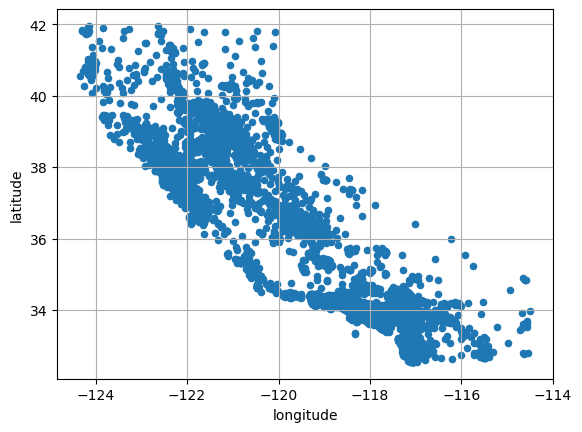

In [9]:
housing.plot(kind="scatter", x="longitude", y="latitude", 
grid=True)
plt.show()

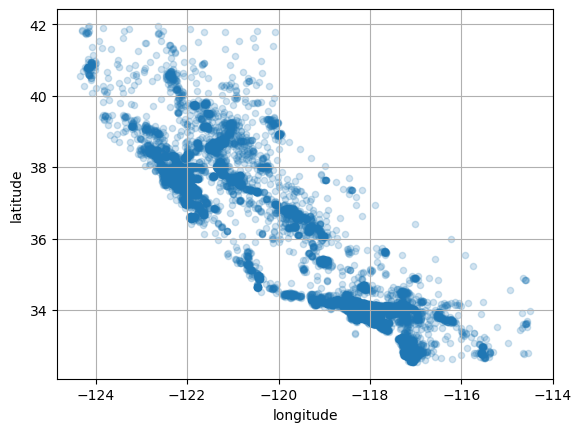

In [10]:
housing.plot(kind="scatter", x="longitude", y="latitude", 
grid=True, alpha=0.2)    # setting alpha to 0.2 makes it easier to see where the districts are densely populated
plt.show()

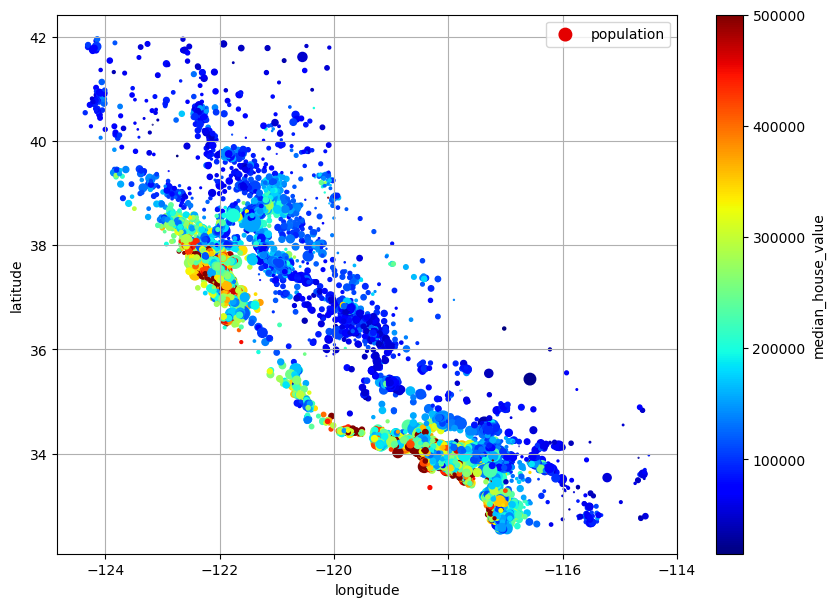

In [11]:
housing.plot(
    kind="scatter",
    x="longitude",
    y="latitude",
    grid=True,
    s=housing["population"] / 100,
    label="population",
    c="median_house_value",
    cmap="jet",
    colorbar=True,
    legend=True,
    sharex=False,
    figsize=(10, 7)
)

plt.show()

### Correlation of each attribute with median house value

In [12]:
housing.corr(numeric_only=True)  # This will not consider the ocean proximity since it is a categorical column.

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
longitude,1.000000,-0.924213,-0.102937,0.044558,0.068210,0.104236,0.054261,-0.016542,-0.050859
latitude,-0.924213,1.000000,0.005692,-0.036753,-0.066391,-0.115677,-0.071604,-0.078137,-0.139584
housing_median_age,-0.102937,0.005692,1.000000,-0.361710,-0.317978,-0.301906,-0.300075,-0.127043,0.102175
total_rooms,0.044558,-0.036753,-0.361710,1.000000,0.930076,0.863967,0.916143,0.197720,0.137455
total_bedrooms,0.068210,-0.066391,-0.317978,0.930076,1.000000,0.886200,0.978822,-0.006038,0.054635
population,0.104236,-0.115677,-0.301906,0.863967,0.886200,1.000000,0.916237,0.004282,-0.020153
households,0.054261,-0.071604,-0.300075,0.916143,0.978822,0.916237,1.000000,0.013637,0.071426
median_income,-0.016542,-0.078137,-0.127043,0.197720,-0.006038,0.004282,0.013637,1.000000,0.688380
median_house_value,-0.050859,-0.139584,0.102175,0.137455,0.054635,-0.020153,0.071426,0.688380,1.000000


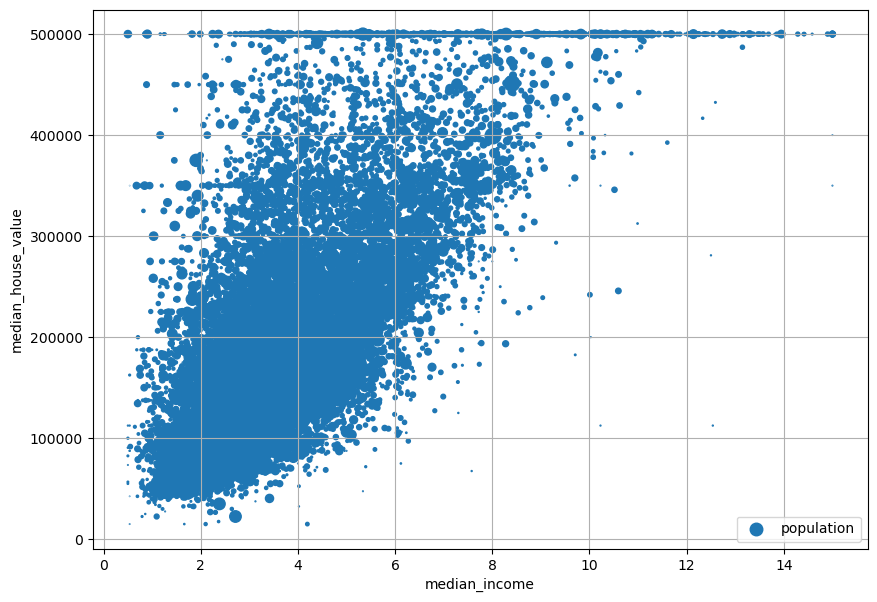

In [13]:
# from housing.corr() we saw median_income and median_house_value has strong correlation 0.688. This diagram prove that strong correlation visually.
housing.plot(
    kind="scatter",
    x="median_income",
    y="median_house_value",
    grid=True,
    s=housing["population"] / 100,
    label="population",
    legend=True,
    sharex=False,
    figsize=(10, 7)
)

plt.show()

# Prepare Data for ML Algorithm

In [14]:
# Separte into housing input and housing label (target)
housing = strat_train_set.drop("median_house_value", axis=1)  
housing_labels = strat_train_set["median_house_value"].copy()

## Data Cleaning
Most Machine Learning algorithms cannot work with missing features, we have 3 option to take care of this:-

1. Remove the district missing the feature
2. Remove the feature column
3. Fill the missing feature with somethng (0, mean, median) called imputation. we go with this option since it is least destructive of the other options. But this imputation can work only on numerical column not on categorical like Ocean_Proximity.

In [15]:
# housing.dropna(subset=["total_bedrooms"], inplace=True)  # option 1
# housing.drop("total_bedrooms", axis=1)  # option 2
median = housing["total_bedrooms"].median()  # option 3
housing["total_bedrooms"].fillna(median, inplace=True)


In [16]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(missing_values=np.nan, strategy="median")

housing_num = housing.select_dtypes(include=[np.number])  # select only numerical columns, since median is not defined for categorical columns
imputer.fit(housing_num)
housing_num = imputer.transform(housing_num)      # check fit_transform() Method  which is more efficient
imputer.statistics_                               # this is .fit() computed result in array


array([-118.51  ,   34.26  ,   29.    , 2125.    ,  434.    , 1167.    ,
        408.    ,    3.5385])

> ### 💡 **KEY NOTE**
>
> Scikit-Learn transformers usually output **NumPy arrays** (or sometimes **SciPy sparse matrices**), even when given a Pandas DataFrame.
>
> So, `imputer.transform(housing_num)` returns a **NumPy array** — meaning it has **no column names or index**.
>
> Luckily, we can easily wrap it back into a **DataFrame** and recover the column names and index from `housing_num`.


In [17]:
housing_num = pd.DataFrame(
    housing_num,
    columns=housing.select_dtypes(include=[np.number]).columns
)

housing_num.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
count,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000
mean,-119.573125,35.637746,28.577156,2639.402798,537.881298,1425.513929,499.990189,3.870428
std,2.000624,2.133294,12.585738,2185.287466,421.831667,1094.795467,382.865787,1.891936
min,-124.350000,32.550000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900
25%,-121.800000,33.930000,18.000000,1447.000000,297.000000,787.000000,279.000000,2.562500
50%,-118.510000,34.260000,29.000000,2125.000000,434.000000,1167.000000,408.000000,3.538500
75%,-118.010000,37.720000,37.000000,3154.000000,642.000000,1726.000000,603.000000,4.750000
max,-114.490000,41.950000,52.000000,39320.000000,6210.000000,16305.000000,5358.000000,15.000100


> ### 💡 **KEY NOTE — Advanced Imputation**
>
> Besides `SimpleImputer`, there are more advanced options for handling missing values:
>
> **🔹 KNNImputer**
> Replaces a missing value using the values of the **k nearest similar observations**.
>
> **🔹 IterativeImputer**
> Treats the missing value more like a **prediction problem** — it uses the other features to estimate the missing value.
>
> **In short:**
> `SimpleImputer` → simple statistical replacement
> `KNNImputer` → uses similar observations
> `IterativeImputer` → predicts using other features


## Handling Text and Categorical Attributes
We have just one text attribute which is ocean_proximity. 

In [18]:
housing_cat = housing[["ocean_proximity"]]  
housing_cat.head(4)

,ocean_proximity
13096,NEAR BAY
14973,<1H OCEAN
3785,INLAND
14689,INLAND


The ML model prefer working with number hence we convert the category into numerical attribute using scikit learn's OrdinalEncoder class.

In [19]:
from sklearn.preprocessing import OrdinalEncoder
ordinal_encoder = OrdinalEncoder()

housing_cat_encoded = ordinal_encoder.fit_transform(housing_cat)
housing_cat_encoded[:8]

array([[3.],
       [0.],
       [1.],
       [1.],
       [4.],
       [1.],
       [0.],
       [3.]])

The categorical attributes are now represented by numbers. One issue with this representation is that the ML algorithm will assume that nearby values are more similar than distant ones. This maybe fine for some category (Ex. good, better, worse) but this is not the case with ocean_proximity (Ex. category 0 and 4 are more similar than 0 and 1). We solve this issue using one-hot incoding.

In [20]:
from sklearn.preprocessing import OneHotEncoder
cat_encoder = OneHotEncoder()
housing_cat_1hot = cat_encoder.fit_transform(housing_cat)

housing_cat_1hot

<16512x5 sparse matrix of type '<class 'numpy.float64'>'
	with 16512 stored elements in Compressed Sparse Row format>

> ### OneHotEncoding
>
> By default, the output of a `OneHotEncoder` is a **SciPy sparse matrix**, instead of a **NumPy array**.
>
> **The one-hot representation looks like**
>
> ```text
> INLAND      = [1,0,0,0,0]
>
> NEAR OCEAN  = [0,0,0,1,0]
>
> <1H OCEAN   = [0,0,0,0,1]
> ```
>
> A **sparse matrix** is a very efficient representation for matrices that contain mostly zeroes. Internally it only stores the non-zero values and their positions.
>
> **Most importantly the algorithm does not learn distance between each categories.**


# Feature Scaling and Transformation

Ml algorithm don't perform well when the attributes has very different scale. This is the case for the housing data: the total number of rooms ranges from about 6 to 39,320, while the median incomes only range from 0 to 15. Without any scaling, most  odels will be biased towards ignoring the median income, and focusing more on the number of rooms. There are two way to have features on same scale: min max scaling and standardization.

Min-max scalling is also called normalization and it is arranging the value in range 0-1 (this range can be modified). But this scaling is much affected by extreme value or outlier since we are using min and max values, the skewness still remains with this scaling.

Besides we apply the scaling to the training set only since we dont want the model to get any information about the test set. The test set could have a value less than xmin and more than xmax of the traing set, hence can be out of the scaled range.

In [21]:
from sklearn.preprocessing import MinMaxScaler
min_max_scaler = MinMaxScaler(feature_range=(-1,1))
house_num_min_max_scaled = min_max_scaler.fit_transform(housing_num)
house_num_min_max_scaled[:5]

array([[-0.60851927,  0.11702128,  1.        , -0.83117147, -0.64116605,
        -0.80701754, -0.61433638, -0.7794789 ],
       [ 0.21095335, -0.66170213,  0.52941176, -0.90014752, -0.88629409,
        -0.91866029, -0.86708979, -0.22929339],
       [-0.51926978,  0.23617021,  0.25490196, -0.94501246, -0.93042358,
        -0.93141946, -0.92458466, -0.73336919],
       [ 0.46855984, -0.74468085, -0.37254902, -0.78778168, -0.7262039 ,
        -0.77401546, -0.70916558, -0.75698266],
       [ 0.25760649, -0.74042553,  0.37254902, -0.77801516, -0.6102432 ,
        -0.76579561, -0.56281501, -0.58217128]])

Standardization : is less affected by outlier. And is calculated by  z = x - mean  / standard_deviation.   x- mean center the data around 0 and diving by s_d count not normal spread bu how far it is from s_d.

In [22]:
from sklearn.preprocessing import StandardScaler
standard_scaler = StandardScaler()
housing_num_std_scaled = standard_scaler.fit_transform(housing_num)
housing_num_std_scaled[:5]

array([[-1.42303652,  1.0136059 ,  1.86111875,  0.31191221,  1.36816703,
         0.13746004,  1.39481249, -0.93649149],
       [ 0.59639445, -0.702103  ,  0.90762971, -0.30861991, -0.43592476,
        -0.69377062, -0.37348471,  1.17194198],
       [-1.2030985 ,  1.27611874,  0.35142777, -0.71224036, -0.76070869,
        -0.78876841, -0.77572662, -0.75978881],
       [ 1.23121557, -0.88492444, -0.91989094,  0.70226169,  0.74230601,
         0.38317548,  0.73137454, -0.85028088],
       [ 0.71136206, -0.87554898,  0.58980003,  0.79012465,  1.59575285,
         0.44437597,  1.75526303, -0.18036472]])

When a feature's distribution has a heavy tail, scaling will squash most values into small range. So before scaling we should try to shrink the noise using several method like sqrt, exponenting with 0-1 or taking log.

when a dataset has several mode (accumulation points) instead of trying to make it exactly smooth we can generate new feature. Radil basis function kernel (rbf_kernel) just do that. In our example it is calculation how close is the housing_median_age to age 35, the more is the age close to 35 the higher the output of this function (max ~ 1) and the farther from 35 the output cloe to 0.  age_similarity_to35 = e ^ ( - gamma (x_ - 35)^2). 

In [23]:
from sklearn.metrics.pairwise import rbf_kernel
age_simil_35 = rbf_kernel(housing[["housing_median_age"]], [[35]], gamma=0.1 )




So far we have played with the input features and not with the target. If the target (median_house_value) is skewed we may take its logarithm, and now the model will now predict log of median_house_value (i.e., we have to exponentiate the prediction to get the correct house_value in dollar). For this scikit-learn provide inverse_transform() method making it easy for us to compute their transformation inverse.

In the following example we use just one input (median_income) to train the model for simplicity. Note: we convert pandas series to DataFrame since StandardScalar expects 2D input.

In [24]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
target_scaler = StandardScaler()
scaled_labels = target_scaler.fit_transform(housing_labels.to_frame())

model = LinearRegression()
model.fit(
    housing[["median_income"]],  # X: one feature
    scaled_labels               # y: house value
)
some_new_data = housing[["median_income"]].iloc[:5]

scaled_predictions = model.predict(some_new_data)
prediction = target_scaler.inverse_transform(scaled_predictions)

# TransformedTargetRegressor is a wrapper that automatically applies a transformation to the target variable 
# before fitting the model and then applies the inverse transformation to the predictions. i.e., do all the above code simply.

We can also build custom transformer using the sklearn, but we are skipping not neccessary for this project.

# Transformation Pipeline

For this project we have computed many data transfomations that must be computed in the right order. Luckily, Scikit-learn provides a PIPELINE class to help with such sequence of transformation. Here is an example for numerical data, we impute then scale ... 

In [25]:
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

sklearn.set_config(display="diagram")  # Make pipeline diagrams easier to read as beloww output

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("standardize", StandardScaler())
])

num_pipeline



Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('standardize', StandardScaler())])

In [26]:
housing_num_prepared = num_pipeline.fit_transform(housing_num)

print(type(housing_num_prepared))
# Turn the np array to pandas DataFrame
df_housing_num_pipeline = pd.DataFrame(
    housing_num_prepared, 
    columns=num_pipeline.get_feature_names_out(),
    index = housing_num.index)

print(type(df_housing_num_pipeline))
df_housing_num_pipeline.head()


<class 'numpy.ndarray'>
<class 'pandas.core.frame.DataFrame'>


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
0,-1.423037,1.013606,1.861119,0.311912,1.368167,0.137460,1.394812,-0.936491
1,0.596394,-0.702103,0.907630,-0.308620,-0.435925,-0.693771,-0.373485,1.171942
2,-1.203098,1.276119,0.351428,-0.712240,-0.760709,-0.788768,-0.775727,-0.759789
3,1.231216,-0.884924,-0.919891,0.702262,0.742306,0.383175,0.731375,-0.850281
4,0.711362,-0.875549,0.589800,0.790125,1.595753,0.444376,1.755263,-0.180365


So far we have handled the numerical and categorical column separately, but it would be better if we can handle them together. For this we use ColumnTransformer. The following ColumnTransformer apply num_pipeline to the numerical columns and cat_pipeline to the categorical ones.

In [27]:
from sklearn.compose import ColumnTransformer

num_attributes = ["longitude", "latitude", "housing_median_age", "total_rooms", "total_bedrooms", "population", "households", "median_income"]
cat_attributes = ["ocean_proximity"]

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessing = ColumnTransformer([
    ("num", num_pipeline, num_attributes),
    ("cat", cat_pipeline, cat_attributes)
])

ColumnTransformer. Its constructor requires a list of triplets (3tuples), each containing a name (which must be unique and not contain double underscores), a transformer, and a list of names (or indices) ofcolumns that the transformer should be applied to. But listing all feature is tedious so there is a way to achieve that without complete listing.

In [28]:
from sklearn.compose import make_column_selector as selector, make_column_transformer

preprocessing = make_column_transformer(
    (num_pipeline, selector(dtype_include=np.number)),
    (cat_pipeline, selector(dtype_include=object))
)

# Now we’re ready to apply this ColumnTransformer to the housing data

housing_prepared = preprocessing.fit_transform(housing)

### But shorter code doesn't mean better code. For tuning and production using ColumnTransformer with explicit name and explicit column name is better option. It is more readable, and it is self-documenting about what the model actually consumes.

In [29]:
from sklearn.cluster import KMeans
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.metrics.pairwise import rbf_kernel

class ClusterSimilarity(BaseEstimator, TransformerMixin):
    def __init__(self, n_clusters=10, gamma=1.0, random_state=None):
        self.n_clusters = n_clusters
        self.gamma = gamma
        self.random_state = random_state

    def fit(self, X, y=None, sample_weight=None):
        self.kmeans_ = KMeans(
            self.n_clusters,
            random_state=self.random_state
        )
        self.kmeans_.fit(X, sample_weight=sample_weight)
        return self  # always return self!

    def transform(self, X):
        return rbf_kernel(
            X,
            self.kmeans_.cluster_centers_,
            gamma=self.gamma
        )

    def get_feature_names_out(self, names=None):
        return [
            f"Cluster {i} similarity"
            for i in range(self.n_clusters)
        ]

# Putting all transformations under one pipeline:
1. Missing value in numerical feature is replaced by median, and in categorical feature replaced by most frequent value.
2. The categorical feature will be one-hot encoded as most ML algorithms only accept numerical values.
3. Few ratio featured will be computed and added:
    bedrooms_ratio, rooms_per_house and people_per_house. Hopefully these will better correlate with the median housing value, and thereby help the ML models
4. A few cluster similarity feature will be added. These would most likely be useful than latitude and longitude.
5. Features with long tail will be replaced by their log
6. All numerical features are standardized.

In [30]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer
import sklearn
from sklearn.compose import ColumnTransformer, make_column_selector
print(sklearn.__version__)

def column_ratio(x):
    return x[:, [0]] / x[:, [1]]

def ratio_pipeline(name=None):
    return make_pipeline(
        SimpleImputer(strategy="median"),
        FunctionTransformer(
            column_ratio,
            feature_names_out=lambda transformer, input_features: [name]
        ),
        StandardScaler()
    )


log_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    FunctionTransformer(np.log, feature_names_out="one-to-one"),
    StandardScaler()
)

cluster_simil = ClusterSimilarity(
    n_clusters=10,
    gamma=1.,
    random_state=42
)

default_num_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler()
)

preprocessing = ColumnTransformer([
    ("bedrooms_ratio", ratio_pipeline("bedrooms_ratio"), ["total_bedrooms", "total_rooms"]),

    ("rooms_per_house", ratio_pipeline("rooms_per_house"), ["total_rooms", "households"]),

    ("people_per_house", ratio_pipeline("people_per_house"), ["population", "households"]),

    ("log", log_pipeline, ["total_bedrooms", "total_rooms", "population","households", "median_income"]),

    ("geo", cluster_simil, ["latitude", "longitude"]),

    ("cat", cat_pipeline, make_column_selector(dtype_include=object))

], remainder=default_num_pipeline)

1.3.2


In [31]:
housing_prepared = preprocessing.fit_transform(housing)
housing_prepared.shape

df_housing_prepared = pd.DataFrame(
    housing_prepared,
    columns=preprocessing.get_feature_names_out(),
    index=housing.index
)

df_housing_prepared.head()

c:\Users\hp\miniconda3\envs\homl3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\Users\hp\miniconda3\envs\homl3\lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\hp\miniconda3\envs\homl3\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "c:\Users\hp\miniconda3\envs\homl3\lib\subprocess.py", line 503, in run
    with Popen(*popenargs, **kwargs) as process:
  File "c:\Users\hp\

,bedrooms_ratio__bedrooms_ratio,rooms_per_house__rooms_per_house,people_per_house__people_per_house,log__total_bedrooms,log__total_rooms,log__population,log__households,log__median_income,geo__Cluster 0 similarity,geo__Cluster 1 similarity,...,geo__Cluster 6 similarity,geo__Cluster 7 similarity,geo__Cluster 8 similarity,geo__Cluster 9 similarity,cat__ocean_proximity_<1H OCEAN,cat__ocean_proximity_INLAND,cat__ocean_proximity_ISLAND,cat__ocean_proximity_NEAR BAY,cat__ocean_proximity_NEAR OCEAN,remainder__housing_median_age
13096,1.846624,-0.866027,-0.330204,1.324114,0.637892,0.456906,1.310369,-1.071522,8.708837e-08,9.712456e-01,...,7.114441e-04,3.070969e-17,1.314047e-01,5.740031e-01,0.0,0.0,0.0,1.0,0.0,1.861119
14973,-0.508121,0.024550,-0.253616,-0.252671,-0.063576,-0.711654,-0.142030,1.194712,1.181328e-01,9.738096e-14,...,3.045359e-27,5.437838e-01,1.735342e-09,2.275194e-10,1.0,0.0,0.0,0.0,0.0,0.907630
3785,-0.202155,-0.041193,-0.051041,-0.925266,-0.859927,-0.941997,-0.913030,-0.756981,2.295286e-08,7.457782e-01,...,4.750719e-03,1.605970e-17,2.744847e-01,2.839978e-01,0.0,1.0,0.0,0.0,0.0,0.351428
14689,-0.149006,-0.034858,-0.141475,0.952773,0.943475,0.670700,0.925373,-0.912253,4.618947e-04,3.873884e-20,...,2.916178e-35,7.405721e-01,2.243339e-14,4.218649e-16,0.0,1.0,0.0,0.0,0.0,-0.919891
20507,0.963208,-0.666554,-0.306148,1.437622,1.003590,0.719093,1.481464,0.034537,3.166634e-02,7.905346e-16,...,2.843975e-30,7.501278e-01,2.890866e-11,3.710912e-12,0.0,0.0,0.0,0.0,1.0,0.589800


# Select And Train A Model

In [32]:
from sklearn.linear_model import LinearRegression

lin_reg = make_pipeline(preprocessing, LinearRegression())
lin_reg.fit(housing, housing_labels)


housing_prediction = lin_reg.predict(housing)
print(f"The prediction price is {housing_prediction[:7].round(-2)}")
print(f"The real price is {housing_labels.iloc[:7].values}")

c:\Users\hp\miniconda3\envs\homl3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


The prediction price is [242800. 375900. 127500.  99400. 324600. 193000. 310600.]
The real price is [458300. 483800. 101700.  96100. 361800.  92600. 349300.]


In [33]:
# We chose RMS as perfomance measure 
from sklearn.metrics import mean_squared_error

lin_rmse = mean_squared_error(
    housing_labels,
    housing_prediction,
    squared=False
)

lin_rmse

68647.95686706669

This means our model has prediction error of $68,647. Most districts' medin_house_value is between $120,000 and $265,000 so that's significan error.

 This is an example of a model underfitting the training data. When this happens it can mean that the features do not provide enough information to make good predictions, or that the model is not powerful enough. As we saw in the previous chapter, the main ways to fix underfitting are to select a more powerful model, to feed the training algorithm with better features, or to reduce the constraints on the model. This model is not regularized, which rules out the last option. You could try to add more features, but first you want to try a more complex model to see how it does. We decide to use DecisionTreeRegressor which is complex enough to catch non linear relations too.

In [34]:
from sklearn.tree import DecisionTreeRegressor
tree_reg = make_pipeline(preprocessing, DecisionTreeRegressor(random_state=42))
tree_reg.fit(housing, housing_labels)

housing_prediction = tree_reg.predict(housing)
tree_rmse = mean_squared_error(
    housing_labels, housing_prediction, squared=False
)
tree_rmse

c:\Users\hp\miniconda3\envs\homl3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


0.0

Perfectly predict everything and the difference appears to be 0. This is most likely overfitting and the model remembers too much of the trainign data. We could test this on test set but we dont touch test set until we decide to launch our confident model so we use part of training data as training set and other as test set.

Cross validation a way to chech a model's performance without relying only one one train/test split. If we use only one set the performance score might heavily depend on that selection. In cross-validation we try several splits and average the result of perfomance measure. The figure below demonstrates several classifications. This well generalize how the learned hypothesis perform on unseen data.

Scikit-learn's k-fold cross-validation feature separate the training set into K nonoverlapping sets. The result is array containing 10 evaluation scores.

<p align="center">
  <img src="images/kFoldCrossValidation.png" alt="My diagram">
</p>

In [35]:
from sklearn.model_selection import cross_val_score
tree_rmse = -cross_val_score(tree_reg, housing, housing_labels, scoring="neg_root_mean_squared_error", cv=10)
print(tree_rmse.round(3))
print(tree_rmse.mean())
print(tree_rmse.std())

c:\Users\hp\miniconda3\envs\homl3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\Users\hp\miniconda3\envs\homl3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\Users\hp\miniconda3\envs\homl3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\Users\hp\miniconda3\envs\homl3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 1

[66343.674 63925.253 66874.849 65875.079 65930.738 70664.636 66933.741
 68454.111 70466.638 65996.478]
67146.51973069902
2016.62109208687


## Now the decision tree doesn't look as it looked earlier. 
The Decision Tree has an RMSE of about 66,868, with a standard deviation of about 2,061. You would not have this information if you just used one validation set. But cross-validation comes at the cost of training the model several times, so it is not always feasible. We know there is overfitting because the trainign error is low (actually 0) and validation error is significantly high. Let's now try another model RandomForestRegressesor.

In [36]:
from sklearn.ensemble import RandomForestRegressor
forest_reg = make_pipeline(
    preprocessing,
    RandomForestRegressor(random_state=42)
)

forest_rmse = -cross_val_score(
                                forest_reg, 
                                housing, 
                                housing_labels,
                                scoring="neg_root_mean_squared_error",
                                cv=10
                            )
print(forest_rmse.round(2))
print(forest_rmse.mean())
print(forest_rmse.std())

c:\Users\hp\miniconda3\envs\homl3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\Users\hp\miniconda3\envs\homl3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\Users\hp\miniconda3\envs\homl3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\Users\hp\miniconda3\envs\homl3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 1

[46405.71 47292.32 45667.06 46805.75 45677.31 46983.86 47222.53 49375.69
 47505.96 47232.56]
47016.87463232867
1000.1741561513113


Wow, this is much better Random Forest algorithm really seem better fitting for this task. However, if you train a RandomForest and measure the RMSE on the training set, you will find roughly 17,474: that’s much lower, meaning that there’s still quite a lot of overfitting going on. possible solutions are to simplify the model, constrain it (i.e., regularize it), or get a lot more training data. 

# Fine Tune A Model

One option would be to fiddle with the hyperparameters manually until we find great combination of hyperparameter values. But this is tedious work so we used scikit learn GridSearchCV class.

GridSearchCV is not training one model, but systematically trying many version of same model, where each version has different hyperparameter, and using cross-validation to decide which version generalizes the best.

In [ ]:
from sklearn.model_selection import GridSearchCV

full_pipeline = Pipeline([
("preprocessing", preprocessing),
("random_forest", RandomForestRegressor(random_state=42)),
])
param_grid = [
{'preprocessing__geo__n_clusters': [5, 8, 10],
'random_forest__max_features': [4, 6, 8]},
{'preprocessing__geo__n_clusters': [10, 15],
'random_forest__max_features': [6, 8, 10]},
]
grid_search = GridSearchCV(full_pipeline, param_grid, cv=3, scoring='neg_root_mean_squared_error')
grid_search.fit(housing, housing_labels)

c:\Users\hp\miniconda3\envs\homl3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\Users\hp\miniconda3\envs\homl3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\Users\hp\miniconda3\envs\homl3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\Users\hp\miniconda3\envs\homl3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 1

GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('preprocessing',
                                        ColumnTransformer(remainder=Pipeline(steps=[('simpleimputer',
                                                                                     SimpleImputer(strategy='median')),
                                                                                    ('standardscaler',
                                                                                     StandardScaler())]),
                                                          transformers=[('bedrooms_ratio',
                                                                         Pipeline(steps=[('simpleimputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('functiontransformer',
                                                                                          FunctionTransformer(feature_names_...
                                                                         <sklearn.compose._column_transformer.make_column_selector object at 0x00000152380DE410>)])),
                                       ('random_forest',
                                        RandomForestRegressor(random_state=42))]),
             param_grid=[{'preprocessing__geo__n_clusters': [5, 8, 10],
                          'random_forest__max_features': [4, 6, 8]},
                         {'preprocessing__geo__n_clusters': [10, 15],
                          'random_forest__max_features': [6, 8, 10]}],
             scoring='neg_root_mean_squared_error')

There are two dictionaries in this param_grid, so GridSearchCV will first evaluate all 3 × 3 = 9 combinations of n_clusters and max_features hyperparameter values specified in the first dict, then it will try all 2 × 3 = 6 combinations of hyperparameter values in the second dict. So in total the grid search will explore 9 + 6 = 15 combinations of hyperparameter values, and it will train the pipeline 3 times per combination, since we are using three-fold cross validation. So there will be a grand total of 15 × 3 = 45 rounds of training! It may take a while, but when it is done you can get the best combination of parameters 

# Ensemble Method

Another method to fine tune our model is to try combine models that perform best. The group (enseble) will perform better than individual models specially if individual models make different kind of error.

## Analyze the best models and their error

You will often gain good insights on the problem by inspecting the best models. For example, the RandomForestRegressor can indicate the relative importance of each attribute for making accurate predictions:

In [39]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint
param_distribs = {'preprocessing__geo__n_clusters': randint(low=3, high=50),'random_forest__max_features': randint(low=2, high=20)}
rnd_search = RandomizedSearchCV( full_pipeline, param_distributions=param_distribs, n_iter=10,  cv=3, scoring='neg_root_mean_squared_error', random_state=42)
rnd_search.fit(housing, housing_labels)


c:\Users\hp\miniconda3\envs\homl3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\Users\hp\miniconda3\envs\homl3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\Users\hp\miniconda3\envs\homl3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\Users\hp\miniconda3\envs\homl3\lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 1

RandomizedSearchCV(cv=3,
                   estimator=Pipeline(steps=[('preprocessing',
                                              ColumnTransformer(remainder=Pipeline(steps=[('simpleimputer',
                                                                                           SimpleImputer(strategy='median')),
                                                                                          ('standardscaler',
                                                                                           StandardScaler())]),
                                                                transformers=[('bedrooms_ratio',
                                                                               Pipeline(steps=[('simpleimputer',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('functiontransformer',
                                                                                                FunctionTransformer(feature_...
                                             ('random_forest',
                                              RandomForestRegressor(random_state=42))]),
                   param_distributions={'preprocessing__geo__n_clusters': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x000001524C64AEC0>,
                                        'random_forest__max_features': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x000001524C64ACE0>},
                   random_state=42, scoring='neg_root_mean_squared_error')

In [40]:
final_model = rnd_search.best_estimator_  # includes preprocessing
feature_importances =  final_model["random_forest"].feature_importances_
feature_importances.round(2)

array([0.06, 0.06, 0.05, 0.01, 0.01, 0.01, 0.01, 0.19, 0.01, 0.01, 0.02,
       0.04, 0.01, 0.  , 0.02, 0.01, 0.01, 0.01, 0.01, 0.01, 0.  , 0.  ,
       0.01, 0.  , 0.01, 0.02, 0.02, 0.01, 0.01, 0.01, 0.03, 0.01, 0.01,
       0.01, 0.01, 0.01, 0.01, 0.  , 0.01, 0.01, 0.02, 0.01, 0.01, 0.01,
       0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.  , 0.08,
       0.  , 0.  , 0.  , 0.01])

## Evaluate the model on test set

In [41]:
X_test = strat_test_set.drop("median_house_value", axis=1)
y_test = strat_test_set["median_house_value"].copy()
final_predictions = final_model.predict(X_test)
final_rmse = mean_squared_error(y_test, final_predictions, squared=False)
print(final_rmse)

41549.20158097943
